# Ventana deslizante

Se mantiene un intervalo $[i, j)$ del array y un resumen de su contenido (suma, conteos, máximo) que se actualiza al entrar el elemento de la derecha y salir el de la izquierda, en vez de recalcularlo. Con ventana fija de tamaño $k$:

$$S_{i+1} = S_i - a_i + a_{i+k}$$

Con ventana variable, $j$ avanza siempre y $i$ avanza mientras la ventana incumple la condición. Como cada índice entra y sale como mucho una vez, el recorrido cuesta $O(n)$ en lugar de $O(nk)$ u $O(n^2)$.

## 1. Suma máxima de k elementos consecutivos

Devolver la suma máxima de $k$ elementos consecutivos y dónde empieza. Comprobar contra la fuerza bruta y comparar tiempos.

In [1]:
import random
import timeit
from collections import Counter, deque

def suma_maxima_k(a, k):
    suma = mejor = sum(a[:k])
    inicio = 0
    for j in range(k, len(a)):
        suma += a[j] - a[j - k]
        if suma > mejor:
            mejor, inicio = suma, j - k + 1
    return mejor, inicio

def suma_maxima_k_bruta(a, k):
    return max(sum(a[i:i + k]) for i in range(len(a) - k + 1))

print(suma_maxima_k([2, 1, 5, 1, 3, 2], 3))

random.seed(1)
for _ in range(1000):
    a = [random.randint(-10, 10) for _ in range(random.randint(1, 20))]
    k = random.randint(1, len(a))
    mejor, inicio = suma_maxima_k(a, k)
    assert mejor == suma_maxima_k_bruta(a, k) == sum(a[inicio:inicio + k])

a = [random.randint(-100, 100) for _ in range(50_000)]
for f in (suma_maxima_k, suma_maxima_k_bruta):
    print(f"{f.__name__:20} {timeit.timeit(lambda: f(a, 1_000), number=1):.4f} s")

(9, 2)
suma_maxima_k        0.0031 s
suma_maxima_k_bruta  0.2769 s


## 2. Subcadena más larga sin caracteres repetidos

Usar una ventana variable que guarda la última posición de cada carácter: al encontrar uno repetido dentro de la ventana, el inicio salta justo después de su aparición anterior. Mostrar la traza y comprobar contra la fuerza bruta.

In [2]:
def sin_repetir(s, traza=False):
    ultima, inicio, mejor = {}, 0, (0, 0)
    for j, c in enumerate(s):
        if ultima.get(c, -1) >= inicio:
            inicio = ultima[c] + 1
        ultima[c] = j
        if j + 1 - inicio > mejor[1] - mejor[0]:
            mejor = (inicio, j + 1)
        if traza:
            print(f"{j:2} {c}  ventana {s[inicio:j + 1]!r}")
    return s[mejor[0]:mejor[1]]

def sin_repetir_bruto(s):
    n = len(s)
    return max((s[i:j] for i in range(n) for j in range(i, n + 1) if len(set(s[i:j])) == j - i), key=len, default="")

print(sin_repetir("abcabcbb", traza=True))
for _ in range(1000):
    s = "".join(random.choices("abcd", k=random.randint(0, 12)))
    assert len(sin_repetir(s)) == len(sin_repetir_bruto(s))

 0 a  ventana 'a'
 1 b  ventana 'ab'
 2 c  ventana 'abc'
 3 a  ventana 'bca'
 4 b  ventana 'cab'
 5 c  ventana 'abc'
 6 b  ventana 'cb'
 7 b  ventana 'b'
abc


## 3. Ventana mínima que contiene un patrón

Encontrar la subcadena más corta de un texto que contiene todos los caracteres de un patrón (con sus repeticiones). Ampliar la ventana por la derecha hasta cubrir el patrón y encogerla por la izquierda mientras lo siga cubriendo; el contador `faltan` permite saber en $O(1)$ si la ventana es válida.

In [3]:
def ventana_minima(texto, patron):
    necesita, faltan = Counter(patron), len(patron)
    i, mejor = 0, None
    for j, c in enumerate(texto):
        if necesita[c] > 0:
            faltan -= 1
        necesita[c] -= 1
        while faltan == 0:
            if mejor is None or j + 1 - i < mejor[1] - mejor[0]:
                mejor = (i, j + 1)
            necesita[texto[i]] += 1
            if necesita[texto[i]] > 0:
                faltan += 1
            i += 1
    return texto[mejor[0]:mejor[1]] if mejor else ""

def ventana_minima_bruta(texto, patron):
    objetivo, n = Counter(patron), len(texto)
    candidatas = (texto[i:j] for i in range(n) for j in range(i + 1, n + 1) if not objetivo - Counter(texto[i:j]))
    return min(candidatas, key=len, default="")

for _ in range(500):
    texto = "".join(random.choices("abc", k=random.randint(0, 12)))
    patron = "".join(random.choices("abc", k=random.randint(1, 3)))
    assert len(ventana_minima(texto, patron)) == len(ventana_minima_bruta(texto, patron))
print(ventana_minima("ADOBECODEBANC", "ABC"), repr(ventana_minima("ABC", "AA")))

BANC ''


## 4. Máximo de cada ventana con `deque`

Devolver el máximo de cada ventana de tamaño $k$ en $O(n)$. Una `deque` guarda índices con valores decrecientes: al entrar un elemento se descartan por la derecha los menores o iguales (ya nunca serán el máximo) y por la izquierda el que sale de la ventana, así que el máximo está siempre al frente. Comprobar contra la fuerza bruta y dibujarlo sobre una serie aleatoria.

[3, 3, 5, 5, 6, 7]


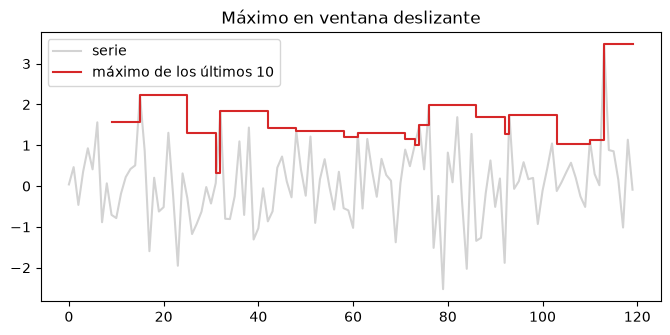

In [4]:
import matplotlib.pyplot as plt

def maximos_ventana(a, k):
    cola, maximos = deque(), []
    for j, x in enumerate(a):
        while cola and a[cola[-1]] <= x:
            cola.pop()
        cola.append(j)
        if cola[0] <= j - k:
            cola.popleft()
        if j >= k - 1:
            maximos.append(a[cola[0]])
    return maximos

for _ in range(1000):
    a = [random.randint(0, 20) for _ in range(random.randint(1, 20))]
    k = random.randint(1, len(a))
    assert maximos_ventana(a, k) == [max(a[i:i + k]) for i in range(len(a) - k + 1)]
print(maximos_ventana([1, 3, -1, -3, 5, 3, 6, 7], 3))

random.seed(4)
serie = [random.gauss(0, 1) for _ in range(120)]
k = 10
fig, eje = plt.subplots(figsize=(8, 3.5))
eje.plot(serie, color="lightgray", label="serie")
eje.step(range(k - 1, len(serie)), maximos_ventana(serie, k), where="post", color="tab:red", label=f"máximo de los últimos {k}")
eje.legend()
eje.set_title("Máximo en ventana deslizante")
plt.show()

## 5. Subarray más corto con suma mínima

Con números positivos, encontrar la longitud del subarray contiguo más corto cuya suma sea al menos `objetivo` (0 si no hay ninguno). Como todos son positivos, quitar elementos por la izquierda solo puede bajar la suma, así que la ventana variable funciona en $O(n)$. Comprobar contra la fuerza bruta.

In [5]:
def mas_corto_con_suma(a, objetivo):
    i, suma, mejor = 0, 0, None
    for j, x in enumerate(a):
        suma += x
        while suma >= objetivo:
            mejor = j + 1 - i if mejor is None else min(mejor, j + 1 - i)
            suma -= a[i]
            i += 1
    return mejor or 0

for _ in range(1000):
    a = [random.randint(1, 10) for _ in range(random.randint(0, 15))]
    t = random.randint(1, 40)
    largos = [j - i for i in range(len(a)) for j in range(i + 1, len(a) + 1) if sum(a[i:j]) >= t]
    assert mas_corto_con_suma(a, t) == min(largos, default=0)
print(mas_corto_con_suma([2, 3, 1, 2, 4, 3], 7), mas_corto_con_suma([1, 1, 1], 5))

2 0
